In [25]:
import json
import numpy as np
import arviz as az

# ---- load ----
idata = az.from_netcdf("idata_clean.nc")

# ---- variables you want to keep as the prior for the new batch ----
PRIOR_VARS = [
    "alpha0", "sigma_alpha",
    "mu_logk", "mu_logEaR",
    "sigma_type_k", "sigma_type_E",
    "sigma", "nu",
    "type_k", "type_E",
    "coform_k", "coform_E",
    # optional but useful to carry over:
 #   "logk", "logEaR", "Ea", "k_ref", "t90_25", "alpha",
]

def _flatten(da):
    """(chain, draw, ...) -> (n_samples, ...) numpy array."""
    return da.stack(sample=("chain", "draw")).values

out = {
    "meta": {
        "format": "arviz-flat-posterior-v1",
        "n_samples": int(idata.posterior.sizes["chain"] * idata.posterior.sizes["draw"]),
        "n_chains":  int(idata.posterior.sizes["chain"]),
        "n_draws":   int(idata.posterior.sizes["draw"]),
        "variables": PRIOR_VARS,
        "dims": {
            k: list(idata.posterior[k].dims)
            for k in PRIOR_VARS
        },
        "coords": {
            k: {d: list(map(int, idata.posterior[k].coords[d].values))}
            for k in PRIOR_VARS
            if any(d in idata.posterior[k].dims
                   for d in idata.posterior[k].dims
                   if d not in ("chain", "draw"))
            for d in idata.posterior[k].dims
            if d not in ("chain", "draw")
        },
    },
    "data": {
        k: _flatten(idata.posterior[k]).tolist()
        for k in PRIOR_VARS
    },
}

with open("study_posterior.json", "w") as f:
    json.dump(out, f)

In [5]:
import json
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import gammaln

R      = 8.314
T_REF  = 278.15
LOG109 = np.log(10.0 / 9.0)

idata        = az.from_netcdf("idata_clean.nc")
enc          = json.load(open("study_posterior.json"))

new_df = pd.read_csv("test_data.csv")
# required columns: time_months, potency, temp_C, temp_K
new_df["log_potency"] = np.log(new_df["potency"].astype(float))

# --- identify this batch's type / coform in the study's encoding ---
NEW_TYPE   = 2        # as integer based on the coords encoding mapping
NEW_COFORM = 1

# Safely extract coordinate lists by getting the first key-value pair's value in the inner coordinate dictionary
type_coords = list(enc["meta"]["coords"]["type_k"].values())[0]
coform_coords = list(enc["meta"]["coords"]["coform_k"].values())[0]

type_idx_new   = type_coords.index(NEW_TYPE)
coform_idx_new = coform_coords.index(NEW_COFORM)

# Filter for 37 °C observations for the new batch
df_37 = new_df[np.isclose(new_df["temp_K"], 310.15, atol=0.05)]
time_37    = df_37["time_months"].values.astype(float)
log_pot_37 = df_37["log_potency"].values.astype(float)
T_37       = 37 + 273.15

In [26]:
def flat(name):
    return idata.posterior[name].stack(sample=("chain", "draw")).values

mu_logk_all          = flat("mu_logk")
mu_logEaR_all        = flat("mu_logEaR")
alpha0_all           = flat("alpha0")
sigma_alpha_all      = flat("sigma_alpha")
sigma_lot_logk_all   = flat("sigma_type_k")
sigma_lot_logEaR_all = flat("sigma_type_E")
sigma_all            = flat("sigma")
nu_all               = flat("nu")
type_k_all           = flat("type_k")
type_E_all           = flat("type_E")
coform_k_all         = flat("coform_k")
coform_E_all         = flat("coform_E")

n_total = len(mu_logk_all)
print(f"{n_total} posterior draws available as the prior for the new batch")

12000 posterior draws available as the prior for the new batch


In [7]:
rng = np.random.default_rng(42)
K   = 200                       # particles per posterior draw

alpha_ks  = np.empty((n_total, K))
logk_ks   = np.empty((n_total, K))
logEaR_ks = np.empty((n_total, K))

for s in range(n_total):
    alpha_ks[s]  = rng.normal(alpha0_all[s], sigma_alpha_all[s], size=K)
    logk_ks[s]   = rng.normal(
        mu_logk_all[s]   + type_k_all[type_idx_new, s]   + coform_k_all[coform_idx_new, s],
        sigma_lot_logk_all[s], size=K)
    logEaR_ks[s] = rng.normal(
        mu_logEaR_all[s] + type_E_all[type_idx_new, s]   + coform_E_all[coform_idx_new, s],
        sigma_lot_logEaR_all[s], size=K)

# Student-t log-likelihood of the 37 °C data for each (s, k)
log_k37 = logk_ks + np.exp(np.clip(logEaR_ks, -50.0, 50.0)) * (1.0/T_REF - 1.0/T_37)
mu_pred = alpha_ks[..., None] - np.exp(log_k37)[..., None] * time_37[None, None, :]

resid   = (log_pot_37[None, None, :] - mu_pred)
sigma_s = sigma_all[:, None, None]
nu_s    = nu_all[:, None, None]

log_lik = (gammaln((nu_s + 1) / 2) - gammaln(nu_s / 2)
           - 0.5 * np.log(nu_s * np.pi)
           - np.log(sigma_s)
           - (nu_s + 1) / 2 * np.log1p((resid / sigma_s) ** 2 / nu_s))
log_w = log_lik.sum(axis=-1)           # (n_total, K)

# --- ESS diagnostic ---
lw   = log_w.ravel()
w    = np.exp(lw - lw.max());  w /= w.sum()
ess  = 1.0 / np.sum(w**2)
print(f"ESS = {ess:.0f} / {len(w)}   "
      f"({'OK' if ess > 500 else 'increase K or reps'})")

# --- SIR resample ---
n_resample = 4000
idx = rng.choice(len(w), size=n_resample, replace=True, p=w)

alpha_post   = alpha_ks.ravel()[idx]
logk_post    = logk_ks.ravel()[idx]
logEaR_post  = logEaR_ks.ravel()[idx]

# Also keep an *unweighted* set for prior-vs-posterior comparison
prior_idx    = rng.choice(n_total*K, size=n_resample, replace=False)
alpha_prior  = alpha_ks.ravel()[prior_idx]
logk_prior   = logk_ks.ravel()[prior_idx]
logEaR_prior = logEaR_ks.ravel()[prior_idx]

ESS = 621974 / 2400000   (OK)


In [8]:
def t90_at(T_C, alpha, logk, logEaR, threshold=90.0):
    T    = T_C + 273.15
    k_T  = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/T))
    return (alpha - np.log(threshold)) / k_T         # months

def t90_model(T_C, logk, logEaR):                    # alpha = log(100)
    T    = T_C + 273.15
    k_T  = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/T))
    return LOG109 / k_T

t90_5_batch   = t90_at( 5, alpha_post, logk_post, logEaR_post)
t90_25_batch  = t90_at(25, alpha_post, logk_post, logEaR_post)
t90_5_model   = t90_model( 5, logk_post, logEaR_post)
t90_25_model  = t90_model(25, logk_post, logEaR_post)

# prior-only (for reference; 37 °C data not used)
t90_5_prior   = t90_at( 5, alpha_prior, logk_prior, logEaR_prior)
t90_25_prior  = t90_at(25, alpha_prior, logk_prior, logEaR_prior)

In [9]:
def summary(x, label):
    lo, med, hi = np.percentile(x, [2.5, 50, 97.5])
    print(f"{label:>28s}:  mean = {x.mean():9.2f}   "
          f"median = {med:9.2f}   95 % CI = ({lo:.2f}, {hi:.2f})")

print("\n=== Shelf life of the new batch (months) — batch-specific alpha ===")
summary(t90_5_batch,  "t90 @ 5 °C")
summary(t90_25_batch, "t90 @ 25 °C")

print("\n=== Shelf life using the model's alpha = log(100) ===")
summary(t90_5_model,  "t90 @ 5 °C (model alpha)")
summary(t90_25_model, "t90 @ 25 °C (model alpha)")

print("\n=== Prior-only (37 °C data NOT used) — reference ===")
summary(t90_5_prior,  "t90 @ 5 °C (prior)")
summary(t90_25_prior, "t90 @ 25 °C (prior)")

print("\n=== Posterior probabilities ===")
for tau in [12, 18, 24, 36, 48, 60]:
    p5  = float(np.mean(t90_5_batch  >= tau))
    p25 = float(np.mean(t90_25_batch >= tau))
    print(f"P(t90@5°C ≥ {tau:>2d} mo) = {p5:.3f}     "
          f"P(t90@25°C ≥ {tau:>2d} mo) = {p25:.3f}")

print("\n=== What did the 37 °C data actually buy us? ===")
def width(x): return np.percentile(x, 97.5) - np.percentile(x, 2.5)
print(f"t90@5 °C : prior 95% width = {width(t90_5_prior):9.2f}  "
      f"posterior 95% width = {width(t90_5_batch):9.2f}")
print(f"t90@25°C : prior 95% width = {width(t90_25_prior):9.2f}  "
      f"posterior 95% width = {width(t90_25_batch):9.2f}")


=== Shelf life of the new batch (months) — batch-specific alpha ===
                  t90 @ 5 °C:  mean =    209.00   median =    197.00   95 % CI = (113.01, 376.79)
                 t90 @ 25 °C:  mean =     12.46   median =     12.00   95 % CI = (8.29, 19.41)

=== Shelf life using the model's alpha = log(100) ===
    t90 @ 5 °C (model alpha):  mean =    212.09   median =    196.05   95 % CI = (125.75, 385.98)
   t90 @ 25 °C (model alpha):  mean =     12.79   median =     11.98   95 % CI = (8.42, 22.03)

=== Prior-only (37 °C data NOT used) — reference ===
          t90 @ 5 °C (prior):  mean =    175.32   median =    164.71   95 % CI = (61.49, 352.91)
         t90 @ 25 °C (prior):  mean =      8.96   median =      8.23   95 % CI = (2.34, 20.45)

=== Posterior probabilities ===
P(t90@5°C ≥ 12 mo) = 1.000     P(t90@25°C ≥ 12 mo) = 0.499
P(t90@5°C ≥ 18 mo) = 1.000     P(t90@25°C ≥ 18 mo) = 0.041
P(t90@5°C ≥ 24 mo) = 1.000     P(t90@25°C ≥ 24 mo) = 0.006
P(t90@5°C ≥ 36 mo) = 1.000     P(t

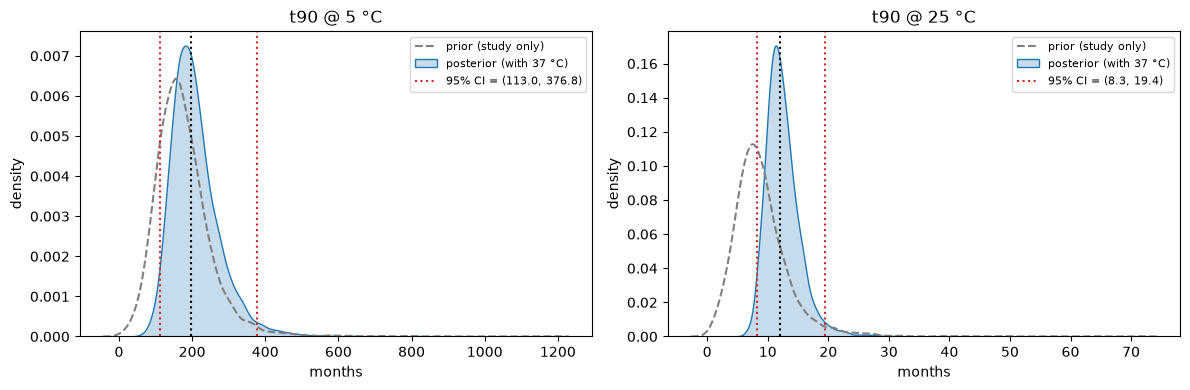

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, post, prior, label in [
    (axes[0], t90_5_batch,  t90_5_prior,  "t90 @ 5 °C"),
    (axes[1], t90_25_batch, t90_25_prior, "t90 @ 25 °C"),
]:
    sns.kdeplot(prior, ax=ax, color="grey",  label="prior (study only)", ls="--")
    sns.kdeplot(post,  ax=ax, color="C0",    label="posterior (with 37 °C)", fill=True)

    lo, med, hi = np.percentile(post, [2.5, 50, 97.5])
    ax.axvline(med, color="k", ls=":")
    ax.axvline(lo,  color="C3", ls=":", label=f"95% CI = ({lo:.1f}, {hi:.1f})")
    ax.axvline(hi,  color="C3", ls=":")
    ax.set(xlabel="months", ylabel="density", title=label)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
rng = np.random.default_rng(42)
K   = 20                       # particles per posterior draw

alpha_ks  = np.empty((n_total, K))
logk_ks   = np.empty((n_total, K))
logEaR_ks = np.empty((n_total, K))

for s in range(n_total):
    alpha_ks[s]  = rng.normal(alpha0_all[s], sigma_alpha_all[s], size=K)
    logk_ks[s]   = rng.normal(
        mu_logk_all[s]   + type_k_all[type_idx_new, s]   + coform_k_all[coform_idx_new, s],
        sigma_lot_logk_all[s], size=K)
    logEaR_ks[s] = rng.normal(
        mu_logEaR_all[s] + type_E_all[type_idx_new, s]   + coform_E_all[coform_idx_new, s],
        sigma_lot_logEaR_all[s], size=K)

# Student-t log-likelihood of the 37 °C data for each (s, k)
log_k37 = logk_ks + np.exp(np.clip(logEaR_ks, -50.0, 50.0)) * (1.0/T_REF - 1.0/T_37)
mu_pred = alpha_ks[..., None] - np.exp(log_k37)[..., None] * time_37[None, None, :]

resid   = (log_pot_37[None, None, :] - mu_pred)
sigma_s = sigma_all[:, None, None]
nu_s    = nu_all[:, None, None]

log_lik = (gammaln((nu_s + 1) / 2) - gammaln(nu_s / 2)
           - 0.5 * np.log(nu_s * np.pi)
           - np.log(sigma_s)
           - (nu_s + 1) / 2 * np.log1p((resid / sigma_s) ** 2 / nu_s))
log_w = log_lik.sum(axis=-1)           # (n_total, K)

# --- ESS diagnostic ---
lw   = log_w.ravel()
w    = np.exp(lw - lw.max());  w /= w.sum()
ess  = 1.0 / np.sum(w**2)
print(f"ESS = {ess:.0f} / {len(w)}   "
      f"({'OK' if ess > 500 else 'increase K or reps'})")

# --- SIR resample ---
n_resample = 4000
idx = rng.choice(len(w), size=n_resample, replace=True, p=w)

alpha_post   = alpha_ks.ravel()[idx]
logk_post    = logk_ks.ravel()[idx]
logEaR_post  = logEaR_ks.ravel()[idx]

# Also keep an *unweighted* set for prior-vs-posterior comparison
prior_idx    = rng.choice(n_total*K, size=n_resample, replace=False)
alpha_prior  = alpha_ks.ravel()[prior_idx]
logk_prior   = logk_ks.ravel()[prior_idx]
logEaR_prior = logEaR_ks.ravel()[prior_idx]

ESS = 62094 / 240000   (OK)


In [12]:
def t90_at(T_C, alpha, logk, logEaR, threshold=90.0):
    T    = T_C + 273.15
    k_T  = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/T))
    return (alpha - np.log(threshold)) / k_T         # months

def t90_model(T_C, logk, logEaR):                    # alpha = log(100)
    T    = T_C + 273.15
    k_T  = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/T))
    return LOG109 / k_T

t90_5_batch   = t90_at( 5, alpha_post, logk_post, logEaR_post)
t90_25_batch  = t90_at(25, alpha_post, logk_post, logEaR_post)
t90_5_model   = t90_model( 5, logk_post, logEaR_post)
t90_25_model  = t90_model(25, logk_post, logEaR_post)

# prior-only (for reference; 37 °C data not used)
t90_5_prior   = t90_at( 5, alpha_prior, logk_prior, logEaR_prior)
t90_25_prior  = t90_at(25, alpha_prior, logk_prior, logEaR_prior)

In [13]:
def summary(x, label):
    lo, med, hi = np.percentile(x, [2.5, 50, 97.5])
    print(f"{label:>28s}:  mean = {x.mean():9.2f}   "
          f"median = {med:9.2f}   95 % CI = ({lo:.2f}, {hi:.2f})")

print("\n=== Shelf life of the new batch (months) — batch-specific alpha ===")
summary(t90_5_batch,  "t90 @ 5 °C")
summary(t90_25_batch, "t90 @ 25 °C")

print("\n=== Shelf life using the model's alpha = log(100) ===")
summary(t90_5_model,  "t90 @ 5 °C (model alpha)")
summary(t90_25_model, "t90 @ 25 °C (model alpha)")

print("\n=== Prior-only (37 °C data NOT used) — reference ===")
summary(t90_5_prior,  "t90 @ 5 °C (prior)")
summary(t90_25_prior, "t90 @ 25 °C (prior)")

print("\n=== Posterior probabilities ===")
for tau in [12, 18, 24, 36, 48, 60]:
    p5  = float(np.mean(t90_5_batch  >= tau))
    p25 = float(np.mean(t90_25_batch >= tau))
    print(f"P(t90@5°C ≥ {tau:>2d} mo) = {p5:.3f}     "
          f"P(t90@25°C ≥ {tau:>2d} mo) = {p25:.3f}")

print("\n=== What did the 37 °C data actually buy us? ===")
def width(x): return np.percentile(x, 97.5) - np.percentile(x, 2.5)
print(f"t90@5 °C : prior 95% width = {width(t90_5_prior):9.2f}  "
      f"posterior 95% width = {width(t90_5_batch):9.2f}")
print(f"t90@25°C : prior 95% width = {width(t90_25_prior):9.2f}  "
      f"posterior 95% width = {width(t90_25_batch):9.2f}")


=== Shelf life of the new batch (months) — batch-specific alpha ===
                  t90 @ 5 °C:  mean =    206.41   median =    195.02   95 % CI = (108.54, 370.36)
                 t90 @ 25 °C:  mean =     12.38   median =     11.97   95 % CI = (8.17, 19.02)

=== Shelf life using the model's alpha = log(100) ===
    t90 @ 5 °C (model alpha):  mean =    210.48   median =    194.84   95 % CI = (123.28, 405.68)
   t90 @ 25 °C (model alpha):  mean =     12.76   median =     12.03   95 % CI = (8.41, 21.73)

=== Prior-only (37 °C data NOT used) — reference ===
          t90 @ 5 °C (prior):  mean =    175.31   median =    164.25   95 % CI = (61.81, 348.62)
         t90 @ 25 °C (prior):  mean =      9.01   median =      8.23   95 % CI = (2.40, 21.00)

=== Posterior probabilities ===
P(t90@5°C ≥ 12 mo) = 1.000     P(t90@25°C ≥ 12 mo) = 0.496
P(t90@5°C ≥ 18 mo) = 1.000     P(t90@25°C ≥ 18 mo) = 0.037
P(t90@5°C ≥ 24 mo) = 1.000     P(t90@25°C ≥ 24 mo) = 0.005
P(t90@5°C ≥ 36 mo) = 1.000     P(t

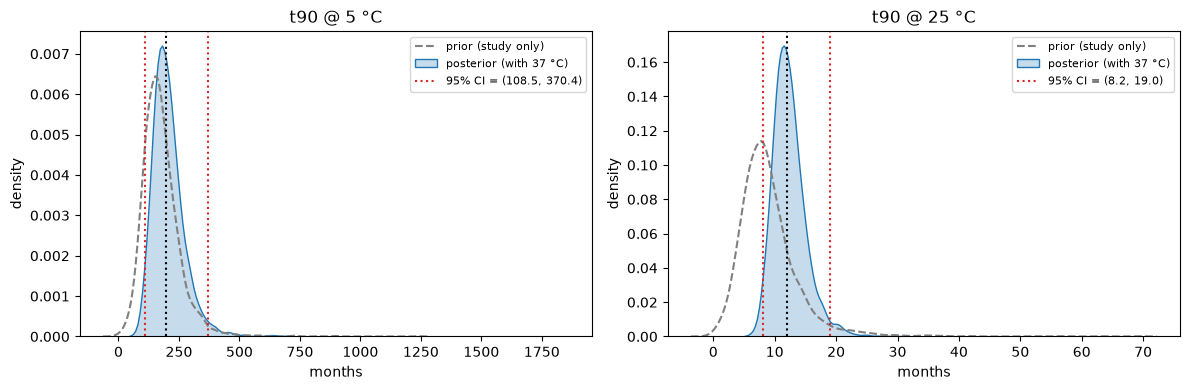

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, post, prior, label in [
    (axes[0], t90_5_batch,  t90_5_prior,  "t90 @ 5 °C"),
    (axes[1], t90_25_batch, t90_25_prior, "t90 @ 25 °C"),
]:
    sns.kdeplot(prior, ax=ax, color="grey",  label="prior (study only)", ls="--")
    sns.kdeplot(post,  ax=ax, color="C0",    label="posterior (with 37 °C)", fill=True)

    lo, med, hi = np.percentile(post, [2.5, 50, 97.5])
    ax.axvline(med, color="k", ls=":")
    ax.axvline(lo,  color="C3", ls=":", label=f"95% CI = ({lo:.1f}, {hi:.1f})")
    ax.axvline(hi,  color="C3", ls=":")
    ax.set(xlabel="months", ylabel="density", title=label)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import gammaln

R      = 8.314
T_REF  = 278.15
LOG109 = np.log(10.0 / 9.0)

# ---- study posterior: direct from .nc ----
idata = az.from_netcdf("idata_clean.nc")

def flat(name):
    """(chain, draw, ...) -> flattened numpy array (n_total, ...)."""
    return idata.posterior[name].stack(sample=("chain", "draw")).values

mu_logk_all          = flat("mu_logk")            # (n_total,)
mu_logEaR_all        = flat("mu_logEaR")
alpha0_all           = flat("alpha0")
sigma_alpha_all      = flat("sigma_alpha")
sigma_lot_logk_all   = flat("sigma_type_k")
sigma_lot_logEaR_all = flat("sigma_type_E")
sigma_all            = flat("sigma")
nu_all               = flat("nu")
type_k_all           = flat("type_k")             # (3, n_total)
type_E_all           = flat("type_E")
coform_k_all         = flat("coform_k")           # (2, n_total)
coform_E_all         = flat("coform_E")

n_total = len(mu_logk_all)
print(f"{n_total} posterior draws — used as prior for the new batch")

# ---- identify this batch's type / coform ----
# 0-based coordinate indices for "type 2" and "coform 1"
NEW_TYPE_INT   = 2
NEW_COFORM_INT = 1

# ---- new-batch 37 °C data ----
new_df = pd.read_csv("test_data.csv")
new_df["log_potency"] = np.log(new_df["potency"].astype(float))

# Filter for 37 °C observations first, then assert on the subset
df_37 = new_df[np.isclose(new_df["temp_K"], 310.15, atol=0.05)]
assert len(df_37) > 0, "No 37 °C data found in test_data.csv!"

time_37    = df_37["time_months"].values.astype(float)
log_pot_37 = df_37["log_potency"].values.astype(float)
T_37       = 37 + 273.15

# ---- IW / SIR ----
rng = np.random.default_rng(42)
K   = 20                                    # particles per posterior draw

alpha_ks  = np.empty((n_total, K))
logk_ks   = np.empty((n_total, K))
logEaR_ks = np.empty((n_total, K))

for s in range(n_total):
    alpha_ks[s]  = rng.normal(alpha0_all[s], sigma_alpha_all[s], size=K)
    logk_ks[s]   = rng.normal(
        mu_logk_all[s]   + type_k_all[NEW_TYPE_INT, s] + coform_k_all[NEW_COFORM_INT, s],
        sigma_lot_logk_all[s], size=K)
    logEaR_ks[s] = rng.normal(
        mu_logEaR_all[s] + type_E_all[NEW_TYPE_INT, s] + coform_E_all[NEW_COFORM_INT, s],
        sigma_lot_logEaR_all[s], size=K)

log_k37 = logk_ks + np.exp(np.clip(logEaR_ks, -50.0, 50.0)) * (1.0/T_REF - 1.0/T_37)
mu_pred = alpha_ks[..., None] - np.exp(log_k37)[..., None] * time_37[None, None, :]
resid   = log_pot_37[None, None, :] - mu_pred

sigma_s = sigma_all[:, None, None]
nu_s    = nu_all[:, None, None]

log_lik = (gammaln((nu_s + 1) / 2) - gammaln(nu_s / 2)
           - 0.5 * np.log(nu_s * np.pi) - np.log(sigma_s)
           - (nu_s + 1) / 2 * np.log1p((resid / sigma_s) ** 2 / nu_s))
log_w = log_lik.sum(axis=-1)                       # (n_total, K)

lw  = log_w.ravel()
w   = np.exp(lw - lw.max());  w /= w.sum()
ess = 1.0 / np.sum(w**2)
print(f"ESS = {ess:.0f} / {len(w)}")

idx = rng.choice(len(w), size=4000, replace=True, p=w)
alpha_post  = alpha_ks.ravel()[idx]
logk_post   = logk_ks.ravel()[idx]
logEaR_post = logEaR_ks.ravel()[idx]

# prior (37 °C not used) — just to compare widths
prior_idx    = rng.choice(n_total*K, size=4000, replace=False)
alpha_prior  = alpha_ks.ravel()[prior_idx]
logk_prior   = logk_ks.ravel()[prior_idx]
logEaR_prior = logEaR_ks.ravel()[prior_idx]

# ---- shelf life ----
def t90_at(T_C, alpha, logk, logEaR):
    k_T = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/(T_C + 273.15)))
    return (alpha - np.log(90.0)) / k_T

def t90_model(T_C, logk, logEaR):
    k_T = np.exp(logk) * np.exp(
        np.exp(np.clip(logEaR, -50.0, 50.0)) * (1.0/T_REF - 1.0/(T_C + 273.15)))
    return LOG109 / k_T

t90_5_batch   = t90_at( 5, alpha_post, logk_post, logEaR_post)
t90_25_batch  = t90_at(25, alpha_post, logk_post, logEaR_post)
t90_5_model   = t90_model( 5, logk_post, logEaR_post)
t90_25_model  = t90_model(25, logk_post, logEaR_post)
t90_5_prior   = t90_at( 5, alpha_prior, logk_prior, logEaR_prior)
t90_25_prior  = t90_at(25, alpha_prior, logk_prior, logEaR_prior)

def summary(x, label):
    lo, med, hi = np.percentile(x, [2.5, 50, 97.5])
    print(f"{label:>32s}:  mean = {x.mean():9.2f}   "
          f"median = {med:9.2f}   95% CI = ({lo:.2f}, {hi:.2f})")

summary(t90_5_batch,  "t90 @ 5 °C  (batch alpha)")
summary(t90_25_batch, "t90 @ 25 °C (batch alpha)")
summary(t90_5_model,  "t90 @ 5 °C  (model alpha = log100)")
summary(t90_25_model, "t90 @ 25 °C (model alpha = log100)")
summary(t90_5_prior,  "t90 @ 5 °C  (prior)")
summary(t90_25_prior, "t90 @ 25 °C (prior)")

12000 posterior draws — used as prior for the new batch
ESS = 62094 / 240000
       t90 @ 5 °C  (batch alpha):  mean =    206.41   median =    195.02   95% CI = (108.54, 370.36)
       t90 @ 25 °C (batch alpha):  mean =     12.38   median =     11.97   95% CI = (8.17, 19.02)
t90 @ 5 °C  (model alpha = log100):  mean =    210.48   median =    194.84   95% CI = (123.28, 405.68)
t90 @ 25 °C (model alpha = log100):  mean =     12.76   median =     12.03   95% CI = (8.41, 21.73)
             t90 @ 5 °C  (prior):  mean =    175.31   median =    164.25   95% CI = (61.81, 348.62)
             t90 @ 25 °C (prior):  mean =      9.01   median =      8.23   95% CI = (2.40, 21.00)


In [17]:
# ============================================================================
# Self-contained simulation with realistic shelf life
# ============================================================================
import numpy as np
import pandas as pd

R      = 8.314
T_REF  = 278.15
LOG109 = np.log(10.0 / 9.0)

# ---- true values -----------------------------------------------------------
TRUE_FIXED = dict(
    alpha0           = np.log(100.0),
    mu_logk          = -6.9,             # was -3.3 → t90_25 ≈ 12 mo
    mu_logEaR        = np.log(9000.0),
    sigma_alpha      = 0.03,
    sigma_lot_logk   = 0.15,
    sigma_lot_logEaR = 0.04,
    sigma            = 0.03,
)
TRUE_TYPE_K   = np.array([-0.2, 0.0, 0.2])
TRUE_TYPE_E   = np.zeros(3)
TRUE_COFORM_K = np.array([-0.02, 0.02])
TRUE_COFORM_E = np.array([-0.02, 0.02])

def _t90(T_C, logk, logEaR, alpha=np.log(100.0)):
    k_T = np.exp(logk) * np.exp(np.exp(logEaR) * (1.0/T_REF - 1.0/(T_C + 273.15)))
    return (alpha - np.log(90.0)) / k_T

def simulate_data(seed=123):
    rng = np.random.default_rng(seed)
    rows, truth_lots = [], []
    lot_counter = 0

    for hpv_type in range(3):
        for coform in range(2):
            for lot in range(4):
                lot_counter += 1

                alpha_j  = rng.normal(TRUE_FIXED["alpha0"], TRUE_FIXED["sigma_alpha"])
                logk_j   = rng.normal(
                    TRUE_FIXED["mu_logk"]   + TRUE_TYPE_K[hpv_type]   + TRUE_COFORM_K[coform],
                    TRUE_FIXED["sigma_lot_logk"])
                logEaR_j = rng.normal(
                    TRUE_FIXED["mu_logEaR"] + TRUE_TYPE_E[hpv_type]   + TRUE_COFORM_E[coform],
                    TRUE_FIXED["sigma_lot_logEaR"])

                truth_lots.append(dict(
                    lot=lot_counter, type=hpv_type, coform=coform,
                    alpha=alpha_j, logk=logk_j, logEaR=logEaR_j))

                for temp_C in (5, 25, 37):
                    T  = temp_C + 273.15
                    kT = np.exp(logk_j) * np.exp(np.exp(logEaR_j) * (1.0/T_REF - 1.0/T))
                    for time in (0, 1, 3, 6, 9, 12):
                        logpot = alpha_j - kT * time + rng.normal(0, TRUE_FIXED["sigma"])
                        rows.append([lot_counter, hpv_type, coform, temp_C, T, time,
                                     np.exp(logpot)])

    df = pd.DataFrame(rows, columns=["lot","type","coform","temp_C","temp_K",
                                     "time_months","potency"])
    df["lot_idx"]     = df["lot"].astype("category").cat.codes
    df["type_idx"]    = df["type"].astype("category").cat.codes
    df["coform_idx"]  = df["coform"].astype("category").cat.codes
    df["log_potency"] = np.log(df["potency"])

    truth = pd.DataFrame(truth_lots)
    truth["lot_idx"]  = truth["lot"].astype("category").cat.codes
    truth["Ea"]       = R * np.exp(truth["logEaR"])
    truth["k_ref"]    = np.exp(truth["logk"])
    truth["t90_5"]    = _t90( 5, truth["logk"], truth["logEaR"])
    truth["t90_25"]   = _t90(25, truth["logk"], truth["logEaR"])
    truth["t90_37"]   = _t90(37, truth["logk"], truth["logEaR"])
    truth["t90_25_model"] = LOG109 / (
        truth["k_ref"] * np.exp(np.exp(truth["logEaR"]) * (1.0/T_REF - 1.0/298.15)))

    return df, truth

In [18]:
df_rep, truth_rep = simulate_data(seed=1000)
print("truth t90_25 range:",
      round(truth_rep["t90_25"].min(), 2), "to", round(truth_rep["t90_25"].max(), 2))
print("truth t90_5  range:",
      round(truth_rep["t90_5"].min(), 1) if "t90_5" in truth_rep
        else "…(see below)", "to",
      round(truth_rep["t90_5"].max(), 1) if "t90_5" in truth_rep else "")

truth t90_25 range: 8.25 to 20.51
truth t90_5  range: 68.8 to 181.8


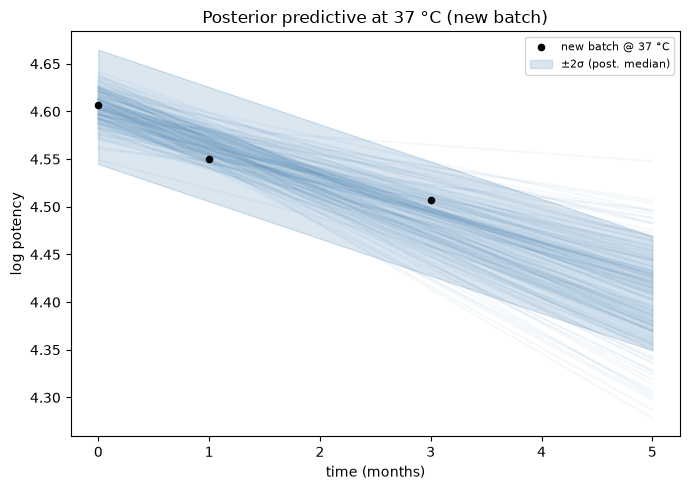

Posterior mean RMSE on the 37 °C data: 0.0150  (σ ≈ 0.0300)


In [19]:
# --- posterior predictive of log-potency at 37 °C ---
n_curve = 100
t_grid  = np.linspace(0, time_37.max() + 2, n_curve)
sel     = rng.choice(len(alpha_post), size=200, replace=False)

k37_post = np.exp(logk_post) * np.exp(
    np.exp(np.clip(logEaR_post, -50.0, 50.0)) * (1.0/T_REF - 1.0/T_37))

fig, ax = plt.subplots(figsize=(7, 5))
for i in sel:
    ax.plot(t_grid,
            alpha_post[i] - k37_post[i] * t_grid,
            color="steelblue", alpha=0.05)
ax.scatter(time_37, log_pot_37, color="black", s=20, zorder=3,
           label="new batch @ 37 °C")
# add noise band from posterior sigma
med_a = np.median(alpha_post[sel]); med_k = np.median(k37_post[sel])
ax.fill_between(t_grid,
                med_a - med_k * t_grid - 2*np.median(sigma_all),
                med_a - med_k * t_grid + 2*np.median(sigma_all),
                color="steelblue", alpha=0.2, label="±2σ (post. median)")
ax.set(xlabel="time (months)", ylabel="log potency",
       title="Posterior predictive at 37 °C (new batch)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# --- scalar check: RMSE between posterior mean prediction and observed log-potency ---
pred_obs = alpha_post[:, None] - k37_post[:, None] * time_37[None, :]
rmse = np.sqrt(np.mean((pred_obs.mean(axis=0) - log_pot_37)**2))
print(f"Posterior mean RMSE on the 37 °C data: {rmse:.4f}  "
      f"(σ ≈ {np.median(sigma_all):.4f})")

In [20]:
df_rep, truth_rep = simulate_data(seed=1000)

print("Per-lot truth ranges (24 lots):")
for col in ("t90_5", "t90_25", "t90_37", "k_ref", "Ea"):
    v = truth_rep[col]
    print(f"  {col:>10s} : {v.min():>10.3f}  →  {v.max():>10.3f}   "
          f"(median {v.median():>10.3f})")

print("\nExpected bands with mu_logk = -6.9, Ea/R = 9000:")
print("  t90_5   ≈  70 – 150 months")
print("  t90_25  ≈   8 –  16 months")
print("  t90_37  ≈   3 –   6 months")

Per-lot truth ranges (24 lots):
       t90_5 :     68.766  →     181.811   (median    108.316)
      t90_25 :      8.247  →      20.511   (median     12.203)
      t90_37 :      2.632  →       6.340   (median      3.877)
       k_ref :      0.001  →       0.002   (median      0.001)
          Ea :  68976.056  →   83507.936   (median  74797.299)

Expected bands with mu_logk = -6.9, Ea/R = 9000:
  t90_5   ≈  70 – 150 months
  t90_25  ≈   8 –  16 months
  t90_37  ≈   3 –   6 months


In [21]:
print("type coords in idata   :", idata.posterior["type_k"].coords["type"].values)
print("coform coords in idata :", idata.posterior["coform_k"].coords["coform"].values)

type coords in idata   : [0 1 2]
coform coords in idata : [0 1]


In [22]:
print(sorted(idata.posterior.data_vars))

['Ea', 'alpha', 'alpha0', 'alpha_raw', 'coform_E', 'coform_E_raw', 'coform_k', 'coform_k_raw', 'corr_k_Ea_empirical', 'k_ref', 'logEaR', 'logEaR_raw', 'logk', 'logk_raw', 'mu_logEaR', 'mu_logk', 'nu', 'sigma', 'sigma_alpha', 'sigma_cf_E', 'sigma_cf_k', 'sigma_lot_logEaR', 'sigma_lot_logk', 'sigma_type_E', 'sigma_type_k', 't90_25', 'type_E', 'type_E_raw', 'type_k', 'type_k_raw']
